# Reducción de imagenes

In [1]:
#Insertamos librerias para la reducción
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy import units as u 
from astropy.visualization import ZScaleInterval
from astropy.coordinates import SkyCoord
from matplotlib import colormaps
from astropy.io import fits
import os
from scipy.optimize import curve_fit



In [2]:
#Abrimos imagenes de ciencia, NGC253, filtro B, 240s
ruta = r'C:\Users\Valem\OneDrive\Escritorio\inst\grupo3\octubre152026'
b1 = fits.open(ruta + r'\NGC_253_B_240.000secs_00000766.fit')
b2 = fits.open(ruta + r'\NGC_253_B_240.000secs_00000767.fit')
b3 = fits.open(ruta + r'\NGC_253_B_240.000secs_00000768.fit')
b4 = fits.open(ruta + r'\NGC_253_B_240.000secs_00000769.fit')
b1[0].header

SIMPLE  =                    T / file does conform to FITS standard             
BITPIX  =                   16 / number of bits per data pixel                  
NAXIS   =                    2 / number of data axes                            
NAXIS1  =                 4096 / length of data axis 1                          
NAXIS2  =                 4096 / length of data axis 2                          
EXTEND  =                    T / FITS dataset may contain extensions            
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
BZERO   =                32768 / offset data range to that of unsigned short    
BSCALE  =                    1 / default scaling factor                         
OBSERVER= 'PUCV    '           / SBIGFITSEXT The name of the observer           
ORIGIN  = 'MAS500  '           / Description of location                        
TELESCOP= 'MAS500  '        

In [3]:
#Abrimos imagenes de ciencia, NGC253, filtro V, 240S
v1 = fits.open(ruta + r'\NGC_253_V_240.000secs_00000762.fit')
v2 = fits.open(ruta + r'\NGC_253_V_240.000secs_00000763.fit')
v3 = fits.open(ruta + r'\NGC_253_V_240.000secs_00000764.fit')
v4 = fits.open(ruta + r'\NGC_253_V_240.000secs_00000765.fit')
v1[0].header

SIMPLE  =                    T / file does conform to FITS standard             
BITPIX  =                   16 / number of bits per data pixel                  
NAXIS   =                    2 / number of data axes                            
NAXIS1  =                 4096 / length of data axis 1                          
NAXIS2  =                 4096 / length of data axis 2                          
EXTEND  =                    T / FITS dataset may contain extensions            
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
BZERO   =                32768 / offset data range to that of unsigned short    
BSCALE  =                    1 / default scaling factor                         
OBSERVER= 'PUCV    '           / SBIGFITSEXT The name of the observer           
ORIGIN  = 'MAS500  '           / Description of location                        
TELESCOP= 'MAS500  '        

In [4]:
#Extraemos las imagenes filtro B
datab1 = b1[0].data
datab2 = b2[0].data
datab3 = b3[0].data
datab4 = b4[0].data

#Extraemos las imagenes filtro V
datav1 = v1[0].data
datav2 = v2[0].data
datav3 = v3[0].data
datav4 = v4[0].data

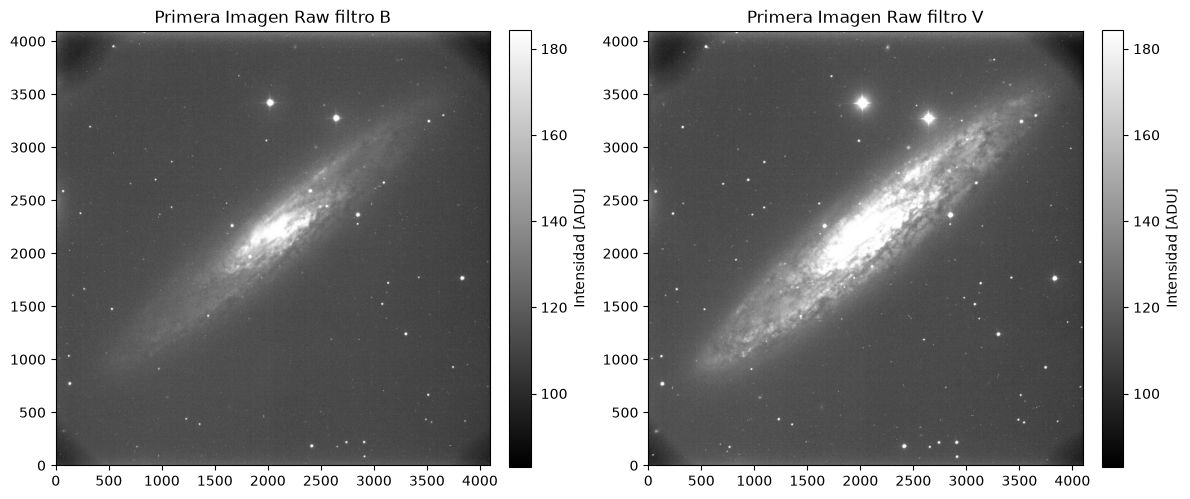

In [5]:
#Graficamos los primeros imagenes
zscale=ZScaleInterval(contrast=0.25)
min_value,max_value=zscale.get_limits(datab1)
min_value,max_value=zscale.get_limits(datav1)

fig,ax=plt.subplots(1,2, figsize=(12,6))
rawb = ax[0].imshow(datab1,vmin=min_value,vmax=max_value,cmap='gray',origin='lower')
ax[0].set_title('Primera Imagen Raw filtro B')
fig.colorbar(rawb, ax=ax[0], label='Intensidad [ADU]', fraction=0.046, pad=0.04)
rawv = ax[1].imshow(datav1,vmin=min_value,vmax=max_value,cmap='gray',origin='lower')
ax[1].set_title('Primera Imagen Raw filtro V')
fig.colorbar(rawv, ax=ax[1], label='Intensidad [ADU]', fraction=0.046, pad=0.04)


plt.tight_layout()
plt.show()

In [6]:
ruta_darks = r'C:\Users\Valem\OneDrive\Escritorio\inst\darks\octubre152026'

In [7]:
# Importamos los darks 120s, 240s y 300s
dark1 = fits.open(ruta_darks + r'\Dark_120.000secs_00000774.fit')[0].data
dark2 = fits.open(ruta_darks + r'\Dark_120.000secs_00000775.fit')[0].data
dark3 = fits.open(ruta_darks + r'\Dark_120.000secs_00000776.fit')[0].data
dark4 = fits.open(ruta_darks + r'\Dark_120.000secs_00000777.fit')[0].data
dark5 = fits.open(ruta_darks + r'\Dark_120.000secs_00000778.fit')[0].data
dark6 = fits.open(ruta_darks + r'\Dark_240.000secs_00000779.fit')[0].data
dark7 = fits.open(ruta_darks + r'\Dark_240.000secs_00000780.fit')[0].data
dark8 = fits.open(ruta_darks + r'\Dark_240.000secs_00000781.fit')[0].data
dark9 = fits.open(ruta_darks + r'\Dark_240.000secs_00000782.fit')[0].data
dark10 = fits.open(ruta_darks + r'\Dark_240.000secs_00000783.fit')[0].data
dark11 = fits.open(ruta_darks + r'\Dark_300.000secs_00000784.fit')[0].data
dark12 = fits.open(ruta_darks + r'\Dark_300.000secs_00000785.fit')[0].data
dark13 = fits.open(ruta_darks + r'\Dark_300.000secs_00000786.fit')[0].data
dark14 = fits.open(ruta_darks + r'\Dark_300.000secs_00000787.fit')[0].data
dark15 = fits.open(ruta_darks + r'\Dark_300.000secs_00000788.fit')[0].data

In [8]:
master_dark120s = np.median(
    [dark1, dark2, dark3, dark4, dark5],
    axis=0
)
master_dark240s = np.median(
    [dark6, dark7, dark8, dark9, dark10],
    axis=0
)
master_dark300s = np.median(
    [dark11, dark12, dark13, dark14, dark15],
    axis=0
)

In [9]:
#Comprobamos las dimensiones
print(master_dark240s.shape)

(4096, 4096)


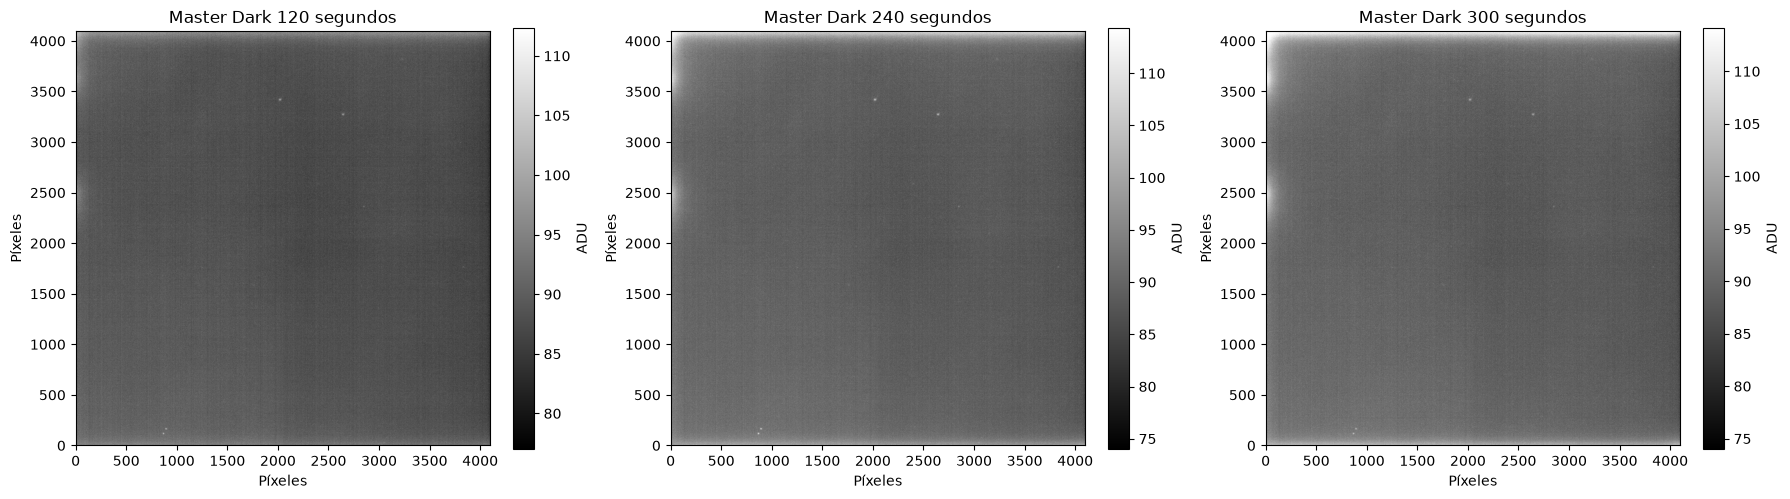

In [10]:
#Graficamos los tres Master Dark
z = ZScaleInterval()

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

darks = [
    (master_dark120s, 'Master Dark 120 segundos'),
    (master_dark240s, 'Master Dark 240 segundos'),
    (master_dark300s, 'Master Dark 300 segundos')
]

for ax, (dark, titulo) in zip(axes, darks):
    vmin, vmax = z.get_limits(dark)

    imagen = ax.imshow(
        dark,
        cmap='gray',
        origin='lower',
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(titulo)
    ax.set_xlabel('Píxeles')
    ax.set_ylabel('Píxeles')

    plt.colorbar(imagen, ax=ax, label='ADU', fraction=0.046)

plt.tight_layout()
plt.show()

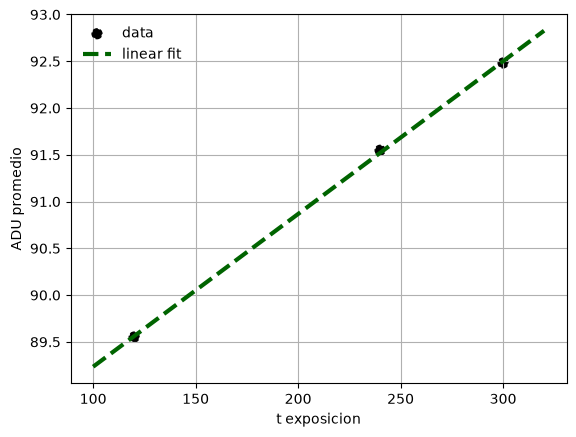

In [11]:
v1 = np.mean(master_dark120s)
v2 = np.mean(master_dark240s)
v3 = np.mean(master_dark300s)

t = [120, 240, 300]
v = [v1, v2, v3]

params, _ = curve_fit(lambda x,a,b: a*x + b, t, v)
a,b = params

t2 = np.linspace(100, 320, 100)

fig = plt.figure()
ax = plt.axes()
ax.scatter(t, v, ls = "--", color = "black", s = 50, label = "data")
ax.plot(t2, a*t2 + b, color = "darkgreen", lw = 3, ls = "--", label = "linear fit") 
ax.set(ylabel = "ADU promedio", xlabel = "t exposicion")
ax.grid()
ax.legend(frameon = False, fontsize = 10)

In [12]:
#Calculamos las dimensiones y los valores estadísticos del Master Dark
print("Dimensiones:", master_dark240s.shape)
print("Mínimo:", np.min(master_dark240s))
print("Máximo:", np.max(master_dark240s))
print("Promedio:", np.mean(master_dark240s))

Dimensiones: (4096, 4096)
Mínimo: 0.0
Máximo: 65535.0
Promedio: 91.54855555295944


In [13]:
dark120s_scaled = master_dark120s*((300*a + b)/(120*a + b))
dark240s_scaled = master_dark120s*((300*a + b)/(240*a + b))

In [14]:
dark120 = dark120s_scaled
dark240 = dark240s_scaled
dark300 = master_dark300s

master_dark = np.median([dark120, dark240, dark300], axis = 0)

# Tiempos de exposición
t1 = 120
t2 = 240
t3 = 300

# Promedio de los tiempos
t_prom = np.mean([t1, t2, t3])

# Promedio de los Master Dark
dark_prom = (dark120 + dark240 + dark300) / 3

# Corriente oscura (pendiente de la recta)
dark_current = (
    (t1 - t_prom) * dark120 +
    (t2 - t_prom) * dark240 +
    (t3 - t_prom) * dark300
) / (
    (t1 - t_prom)**2 +
    (t2 - t_prom)**2 +
    (t3 - t_prom)**2
)

# Bias estimado (intercepto)
master_bias_estimado = dark_prom - dark_current * t_prom

In [15]:
ruta_flats = r'C:\Users\Valem\OneDrive\Escritorio\inst\flats'

In [16]:
#Flats filtro B

flatb1 = fits.open(ruta_flats + r'\FLAT_B_B11-001.fit')[0].data
flatb2 = fits.open(ruta_flats + r'\FLAT_B_B11-002.fit')[0].data
flatb3 = fits.open(ruta_flats + r'\FLAT_B_B11-003.fit')[0].data
flatb4 = fits.open(ruta_flats + r'\FLAT_B_B11-004.fit')[0].data
flatb5 = fits.open(ruta_flats + r'\FLAT_B_B11-005.fit')[0].data
flatb6 = fits.open(ruta_flats + r'\FLAT_B_B11-006.fit')[0].data
flatb7 = fits.open(ruta_flats + r'\FLAT_B_B11-007.fit')[0].data
flatb8 = fits.open(ruta_flats + r'\FLAT_B_B11-008.fit')[0].data
flatb9 = fits.open(ruta_flats + r'\FLAT_B_B11-009.fit')[0].data
flatb10 = fits.open(ruta_flats + r'\FLAT_B_B11-010.fit')[0].data

#Flats filtro V

flatv1 = fits.open(ruta_flats + r'\FLAT_V_B11-001.fit')[0].data
flatv2 = fits.open(ruta_flats + r'\FLAT_V_B11-002.fit')[0].data
flatv3 = fits.open(ruta_flats + r'\FLAT_V_B11-003.fit')[0].data
flatv4 = fits.open(ruta_flats + r'\FLAT_V_B11-004.fit')[0].data
flatv5 = fits.open(ruta_flats + r'\FLAT_V_B11-005.fit')[0].data
flatv6 = fits.open(ruta_flats + r'\FLAT_V_B11-006.fit')[0].data
flatv7 = fits.open(ruta_flats + r'\FLAT_V_B11-007.fit')[0].data
flatv8 = fits.open(ruta_flats + r'\FLAT_V_B11-008.fit')[0].data
flatv9 = fits.open(ruta_flats + r'\FLAT_V_B11-009.fit')[0].data
flatv10 = fits.open(ruta_flats + r'\FLAT_V_B11-010.fit')[0].data

In [17]:
# Revisar tiempo de exposición de los flats B
print("FLATS FILTRO B")
for i in range(1, 11):
    archivo = ruta_flats + rf'\FLAT_B_B11-{i:03d}.fit'
    header = fits.getheader(archivo)
    print(f"Flat B{i:02d}: {header['EXPTIME']} segundos")

# Revisar tiempo de exposición de los flats V
print("\nFLATS FILTRO V")
for i in range(1, 11):
    archivo = ruta_flats + rf'\FLAT_V_B11-{i:03d}.fit'
    header = fits.getheader(archivo)
    print(f"Flat V{i:02d}: {header['EXPTIME']} segundos")

FLATS FILTRO B
Flat B01: 0.5 segundos
Flat B02: 0.5 segundos
Flat B03: 0.5 segundos
Flat B04: 0.5 segundos
Flat B05: 0.5 segundos
Flat B06: 0.5 segundos
Flat B07: 0.5 segundos
Flat B08: 0.5 segundos
Flat B09: 0.5 segundos
Flat B10: 0.5 segundos

FLATS FILTRO V
Flat V01: 0.5 segundos
Flat V02: 0.5 segundos
Flat V03: 0.5 segundos
Flat V04: 0.5 segundos
Flat V05: 0.5 segundos
Flat V06: 0.5 segundos
Flat V07: 1.02 segundos
Flat V08: 1.02 segundos
Flat V09: 1.02 segundos
Flat V10: 1.02 segundos


In [18]:
# Flats corregidos del filtro B

flats_b = [
    flatb1, flatb2, flatb3, flatb4, flatb5,
    flatb6, flatb7, flatb8, flatb9, flatb10
]

normalized_flats_b = np.array([f/np.median(f) for f in flats_b])

master_flatb_norm = np.median(normalized_flats_b, axis=0)

flats_v = [
    flatv1, flatv2, flatv3, flatv4, flatv5,
    flatv6, flatv7, flatv8, flatv9, flatv10
]

normalized_flats_v = np.array([f/np.median(f) for f in flats_v])

master_flatv_norm = np.median(normalized_flats_v, axis=0)


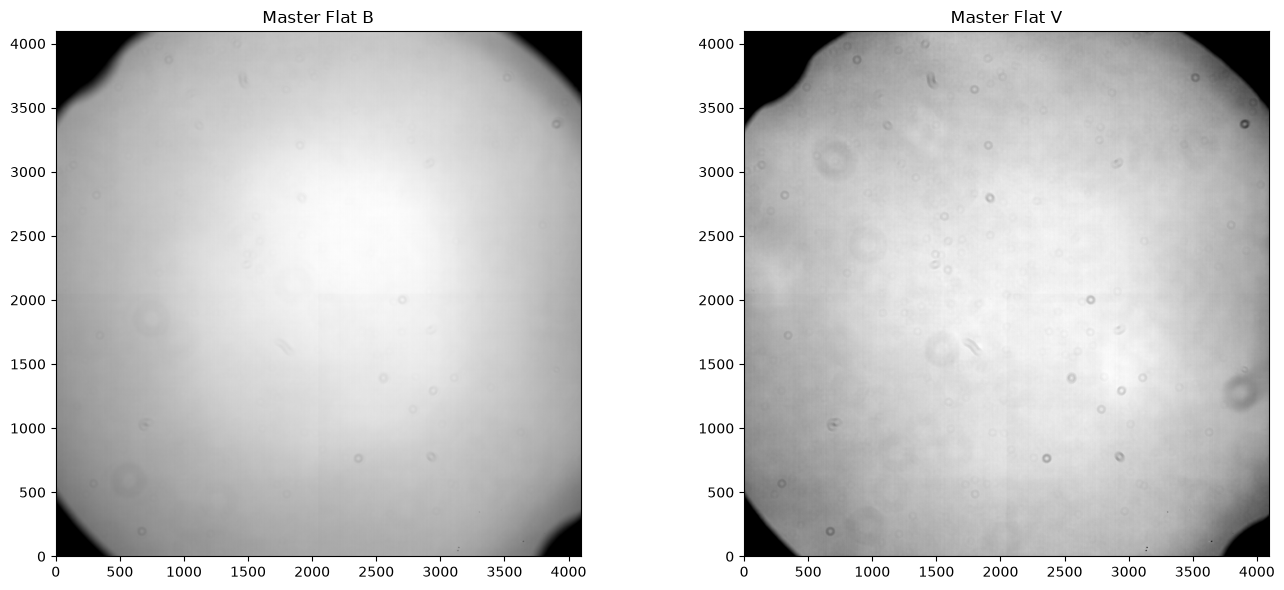

In [19]:
#Graficamos los Flats
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, imagen, titulo in zip(
    axes,
    [master_flatb_norm, master_flatv_norm],
    ['Master Flat B', 'Master Flat V']
):
    z = ZScaleInterval()
    vmin, vmax = z.get_limits(imagen)

    im = ax.imshow(
        imagen,
        cmap='gray',
        origin='lower',
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(titulo)

plt.tight_layout()
plt.show()

In [20]:
imgb1 = np.nan_to_num((datab1-master_dark)/master_flatb_norm, 0.)
imgb2 = np.nan_to_num((datab2-master_dark)/master_flatb_norm, 0.)
imgb3 = np.nan_to_num((datab3-master_dark)/master_flatb_norm, 0.)
imgb4 = np.nan_to_num((datab4-master_dark)/master_flatb_norm, 0.)
imgv1 = np.nan_to_num((datav1-master_dark)/master_flatv_norm, 0.)
imgv2 = np.nan_to_num((datav2-master_dark)/master_flatv_norm, 0.)
imgv3 = np.nan_to_num((datav3-master_dark)/master_flatv_norm, 0.)
imgv4 = np.nan_to_num((datav4-master_dark)/master_flatv_norm, 0.)

C:\Users\Valem\AppData\Local\Temp\ipykernel_20692\3086083393.py:1: RuntimeWarning: invalid value encountered in divide
  imgb1 = np.nan_to_num((datab1-master_dark)/master_flatb_norm, 0.)
C:\Users\Valem\AppData\Local\Temp\ipykernel_20692\3086083393.py:2: RuntimeWarning: invalid value encountered in divide
  imgb2 = np.nan_to_num((datab2-master_dark)/master_flatb_norm, 0.)
C:\Users\Valem\AppData\Local\Temp\ipykernel_20692\3086083393.py:3: RuntimeWarning: invalid value encountered in divide
  imgb3 = np.nan_to_num((datab3-master_dark)/master_flatb_norm, 0.)
C:\Users\Valem\AppData\Local\Temp\ipykernel_20692\3086083393.py:4: RuntimeWarning: invalid value encountered in divide
  imgb4 = np.nan_to_num((datab4-master_dark)/master_flatb_norm, 0.)
C:\Users\Valem\AppData\Local\Temp\ipykernel_20692\3086083393.py:5: RuntimeWarning: invalid value encountered in divide
  imgv1 = np.nan_to_num((datav1-master_dark)/master_flatv_norm, 0.)
C:\Users\Valem\AppData\Local\Temp\ipykernel_20692\3086083393.py:6

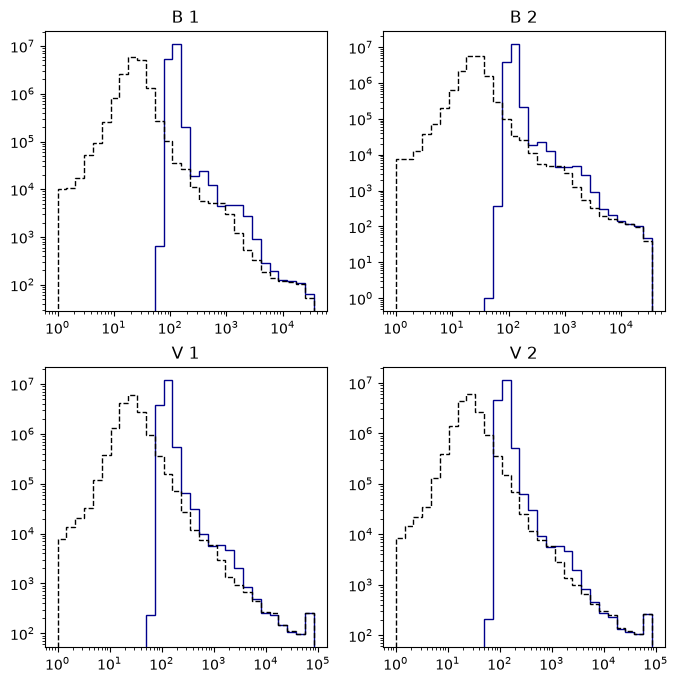

In [21]:
fig, ((ax1,ax2),(ax3,ax4)) = plt.subplots(2,2,figsize = (8,8))
axes = [ax1,ax2,ax3,ax4]
data = [datab1, datab2, datav1, datav2]
reduced_data = [imgb1, imgb2, imgv1, imgv2]

for i in range(len(axes)):
    ax = axes[i]
    data_i = data[i]
    img = reduced_data[i]
    
    ax.hist(data_i.flatten(), log = True, bins = np.logspace(0,np.log10(img.max()), 30), 
            color = "darkblue", ls = "solid", histtype = "step")
    ax.hist(img.flatten(), log = True, bins = np.logspace(0,np.log10(img.max()), 30), 
            color = "black", ls = "--", histtype = "step")
    ax.set_xscale("log")
    ax.set_title(["B 1", "B 2", "V 1", "V 2"][i])

# Reducción

In [22]:
#Creamos las imagenes finales para cada filtro
# Creamos las imágenes finales para el filtro B

mean_image_b = np.mean([datab1, datab2, datab3, datab4], axis = 0)
mean_image_v = np.mean([datav1, datav2, datav3, datav4], axis = 0)

reduced_image_b = (mean_image_b - master_dark - master_bias_estimado)/master_flatb_norm
reduced_image_v = (mean_image_v - master_dark - master_bias_estimado)/master_flatv_norm

#Agregamos la mascara
ruta_bpm = r'C:\Users\Valem\OneDrive\Escritorio\inst'
bpm=fits.open(ruta_bpm + r'\BPM.fit')[0].data

img_final_b = (reduced_image_b*bpm)
img_final_v = (reduced_image_v*bpm)

C:\Users\Valem\AppData\Local\Temp\ipykernel_20692\3637640965.py:7: RuntimeWarning: invalid value encountered in divide
  reduced_image_b = (mean_image_b - master_dark - master_bias_estimado)/master_flatb_norm
C:\Users\Valem\AppData\Local\Temp\ipykernel_20692\3637640965.py:8: RuntimeWarning: invalid value encountered in divide
  reduced_image_v = (mean_image_v - master_dark - master_bias_estimado)/master_flatv_norm


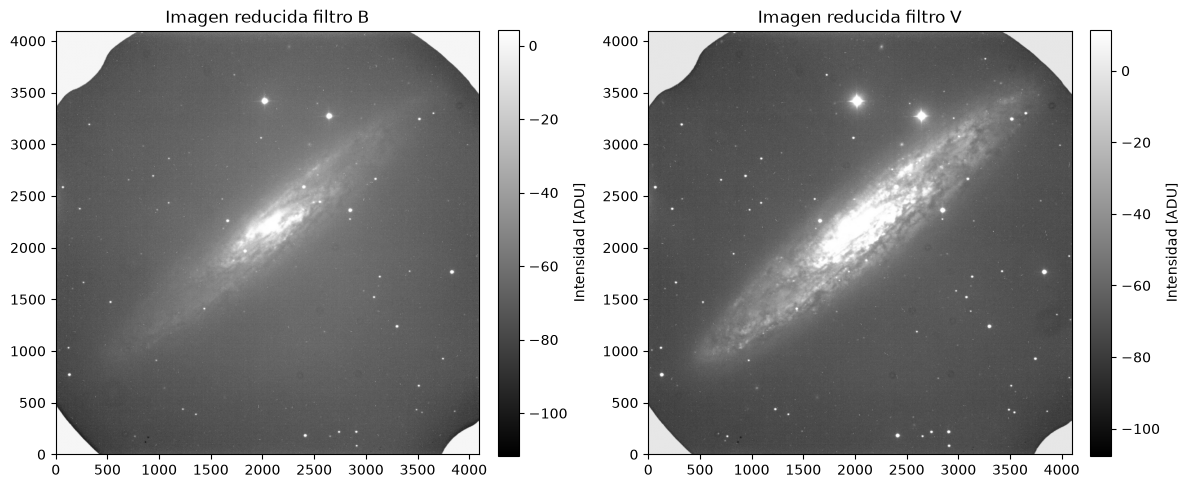

In [23]:
#Graficamos reducidas
zscale = ZScaleInterval(contrast=0.25)
min_b, max_b = zscale.get_limits(img_final_b)
min_v, max_v = zscale.get_limits(img_final_v)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))

im_b = ax[0].imshow(img_final_b, vmin=min_b, vmax=max_b, cmap='gray', origin='lower')
ax[0].set_title('Imagen reducida filtro B')
fig.colorbar(im_b, ax=ax[0], label='Intensidad [ADU]', fraction=0.046, pad=0.04)
im_v = ax[1].imshow(img_final_v, vmin=min_v, vmax=max_v, cmap='gray', origin='lower')
ax[1].set_title('Imagen reducida filtro V')
fig.colorbar(im_v, ax=ax[1], label='Intensidad [ADU]', fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

In [24]:
# Elegimos la carpeta donde guardaremos las imágenes
ruta_guardado = r'C:\Users\Valem\OneDrive\Escritorio\inst'

# Creación FITS y astrometría

phdu = fits.PrimaryHDU(header=b1[0].header, data=img_final_b)
phdu.data = np.float32(phdu.data)

phdu.header['PIXSCALE'] = 0.36
phdu.header['CTYPE1'] = 'RA---TAN'
phdu.header['CTYPE2'] = 'DEC--TAN'
phdu.header['CRPIX1'] = int(phdu.header['NAXIS1']/2)
phdu.header['CRPIX2'] = int(phdu.header['NAXIS2']/2)

coord = SkyCoord(
    f"{phdu.header['OBJCTRA']} {phdu.header['OBJCTDEC']}",
    unit=(u.hourangle, u.deg)
)

phdu.header['CRVAL1'] = coord.ra.value
phdu.header['CRVAL2'] = coord.dec.value

phdu.header['CD1_1'] = -0.0001
phdu.header['CD1_2'] = 0
phdu.header['CD2_1'] = 0
phdu.header['CD2_2'] = 0.0001

phdu.header['OBSERVER'] = 'Cortes, Martinez, Soto'

# Guardamos la imagen B
phdu.writeto(
    os.path.join(ruta_guardado, 'Img_B.fits'),
    overwrite=True
)

In [25]:
phdu_v = fits.PrimaryHDU(header=b1[0].header, data=img_final_v)
phdu_v.data = np.float32(phdu_v.data)

phdu_v.header['PIXSCALE'] = 0.36
phdu_v.header['CTYPE1'] = 'RA---TAN'
phdu_v.header['CTYPE2'] = 'DEC--TAN'
phdu_v.header['CRPIX1'] = int(phdu_v.header['NAXIS1']/2)
phdu_v.header['CRPIX2'] = int(phdu_v.header['NAXIS2']/2)

phdu_v.header['CRVAL1'] = coord.ra.value
phdu_v.header['CRVAL2'] = coord.dec.value

phdu_v.header['CD1_1'] = -0.0001
phdu_v.header['CD1_2'] = 0
phdu_v.header['CD2_1'] = 0
phdu_v.header['CD2_2'] = 0.0001

phdu_v.header['OBSERVER'] = 'Cortes, Martinez, Soto'

phdu_v.writeto(
    os.path.join(ruta_guardado, 'Img_V.fits'),
    overwrite=True
)

In [26]:
# Vemos qué información tiene el FITS creado
test1 = fits.open(os.path.join(ruta_guardado, 'Img_B.fits'))
test1[0].header

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                  -32 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                 4096                                                  
NAXIS2  =                 4096                                                  
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
OBSERVER= 'Cortes, Martinez, Soto' / SBIGFITSEXT The name of the observer       
ORIGIN  = 'MAS500  '           / Description of location                        
TELESCOP= 'MAS500  '           / SBIGFITSEXT The model Telescope                
FOCALLEN=                6500. / SBIGFITSEXT Telescope focal length in mm       
APTDIA  =                 500. / SBIGFITSEXT Aperture diameter in mm            
SBUUID  = '{fac0fa44-d970-46

In [27]:
test2 = fits.open(os.path.join(ruta_guardado, 'Img_V.fits'))
test2[0].header

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                  -32 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                 4096                                                  
NAXIS2  =                 4096                                                  
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
OBSERVER= 'Cortes, Martinez, Soto' / SBIGFITSEXT The name of the observer       
ORIGIN  = 'MAS500  '           / Description of location                        
TELESCOP= 'MAS500  '           / SBIGFITSEXT The model Telescope                
FOCALLEN=                6500. / SBIGFITSEXT Telescope focal length in mm       
APTDIA  =                 500. / SBIGFITSEXT Aperture diameter in mm            
SBUUID  = '{fac0fa44-d970-46

# Estrellas

In [28]:
ruta_estrellas = r"C:\Users\Valem\OneDrive\Escritorio\inst\estrellas"

In [29]:
# HIP 6257

# Filtro B

star_1B_1 = fits.open(ruta_estrellas + r'\HIP_6257_B_70.000secs_00000803.fit')[0].data
star_1B_2 = fits.open(ruta_estrellas + r'\HIP_6257_B_70.000secs_00000804.fit')[0].data
star_1B_3 = fits.open(ruta_estrellas + r'\HIP_6257_B_70.000secs_00000805.fit')[0].data
star_1B_4 = fits.open(ruta_estrellas + r'\HIP_6257_B_70.000secs_00000806.fit')[0].data
star_1B_5 = fits.open(ruta_estrellas + r'\HIP_6257_B_70.000secs_00000807.fit')[0].data

# Filtro V

star_1V_1 = fits.open(ruta_estrellas + r'\HIP_6257_V_5.000secs_00000808.fit')[0].data
star_1V_2 = fits.open(ruta_estrellas + r'\HIP_6257_V_5.000secs_00000809.fit')[0].data
star_1V_3 = fits.open(ruta_estrellas + r'\HIP_6257_V_5.000secs_00000810.fit')[0].data
star_1V_4 = fits.open(ruta_estrellas + r'\HIP_6257_V_5.000secs_00000811.fit')[0].data
star_1V_5 = fits.open(ruta_estrellas + r'\HIP_6257_V_5.000secs_00000812.fit')[0].data
star_1V_6 = fits.open(ruta_estrellas + r'\HIP_6257_V_5.000secs_00000813.fit')[0].data
star_1V_7 = fits.open(ruta_estrellas + r'\HIP_6257_V_5.000secs_00000814.fit')[0].data


# HIP 115796

# Filtro B

star_2B_1 = fits.open(ruta_estrellas + r'\HIP_115796_B_40.000secs_00000791.fit')[0].data
star_2B_2 = fits.open(ruta_estrellas + r'\HIP_115796_B_40.000secs_00000792.fit')[0].data
star_2B_3 = fits.open(ruta_estrellas + r'\HIP_115796_B_40.000secs_00000793.fit')[0].data
star_2B_4 = fits.open(ruta_estrellas + r'\HIP_115796_B_40.000secs_00000794.fit')[0].data
star_2B_5 = fits.open(ruta_estrellas + r'\HIP_115796_B_40.000secs_00000795.fit')[0].data

# Filtro V

star_2V_1 = fits.open(ruta_estrellas+ r'\HIP_115796_V_8.000secs_00000796.fit')[0].data
star_2V_2 = fits.open(ruta_estrellas + r'\HIP_115796_V_8.000secs_00000797.fit')[0].data
star_2V_3 = fits.open(ruta_estrellas + r'\HIP_115796_V_8.000secs_00000798.fit')[0].data
star_2V_4 = fits.open(ruta_estrellas + r'\HIP_115796_V_8.000secs_00000799.fit')[0].data
star_2V_5 = fits.open(ruta_estrellas + r'\HIP_115796_V_8.000secs_00000800.fit')[0].data

In [30]:
ruta_dark_estrellas = r"C:\Users\Valem\OneDrive\Escritorio\inst\dark_estrellas"

In [31]:
# Importamos los darks de estrellas de 5s, 8s, 40s y 70s

# Darks de 5 segundos
dark1e = fits.open(ruta_dark_estrellas + r'\Dark_5.000secs_00000815.fit')[0].data
dark2e = fits.open(ruta_dark_estrellas + r'\Dark_5.000secs_00000816.fit')[0].data
dark3e = fits.open(ruta_dark_estrellas + r'\Dark_5.000secs_00000817.fit')[0].data
dark4e = fits.open(ruta_dark_estrellas + r'\Dark_5.000secs_00000818.fit')[0].data
dark5e = fits.open(ruta_dark_estrellas + r'\Dark_5.000secs_00000819.fit')[0].data

# Darks de 8 segundos
dark6e = fits.open(ruta_dark_estrellas + r'\Dark_8.000secs_00000820.fit')[0].data
dark7e = fits.open(ruta_dark_estrellas + r'\Dark_8.000secs_00000821.fit')[0].data
dark8e = fits.open(ruta_dark_estrellas + r'\Dark_8.000secs_00000822.fit')[0].data
dark9e = fits.open(ruta_dark_estrellas + r'\Dark_8.000secs_00000823.fit')[0].data
dark10e = fits.open(ruta_dark_estrellas + r'\Dark_8.000secs_00000824.fit')[0].data

# Darks de 40 segundos
dark11e = fits.open(ruta_dark_estrellas + r'\Dark_40.000secs_00000825.fit')[0].data
dark12e = fits.open(ruta_dark_estrellas + r'\Dark_40.000secs_00000826.fit')[0].data
dark13e = fits.open(ruta_dark_estrellas + r'\Dark_40.000secs_00000827.fit')[0].data
dark14e = fits.open(ruta_dark_estrellas + r'\Dark_40.000secs_00000828.fit')[0].data
dark15e = fits.open(ruta_dark_estrellas + r'\Dark_40.000secs_00000829.fit')[0].data

# Darks de 70 segundos
dark16e = fits.open(ruta_dark_estrellas + r'\Dark_70.000secs_00000830.fit')[0].data
dark17e = fits.open(ruta_dark_estrellas + r'\Dark_70.000secs_00000831.fit')[0].data
dark18e = fits.open(ruta_dark_estrellas + r'\Dark_70.000secs_00000832.fit')[0].data
dark19e = fits.open(ruta_dark_estrellas + r'\Dark_70.000secs_00000833.fit')[0].data
dark20e = fits.open(ruta_dark_estrellas + r'\Dark_70.000secs_00000834.fit')[0].data

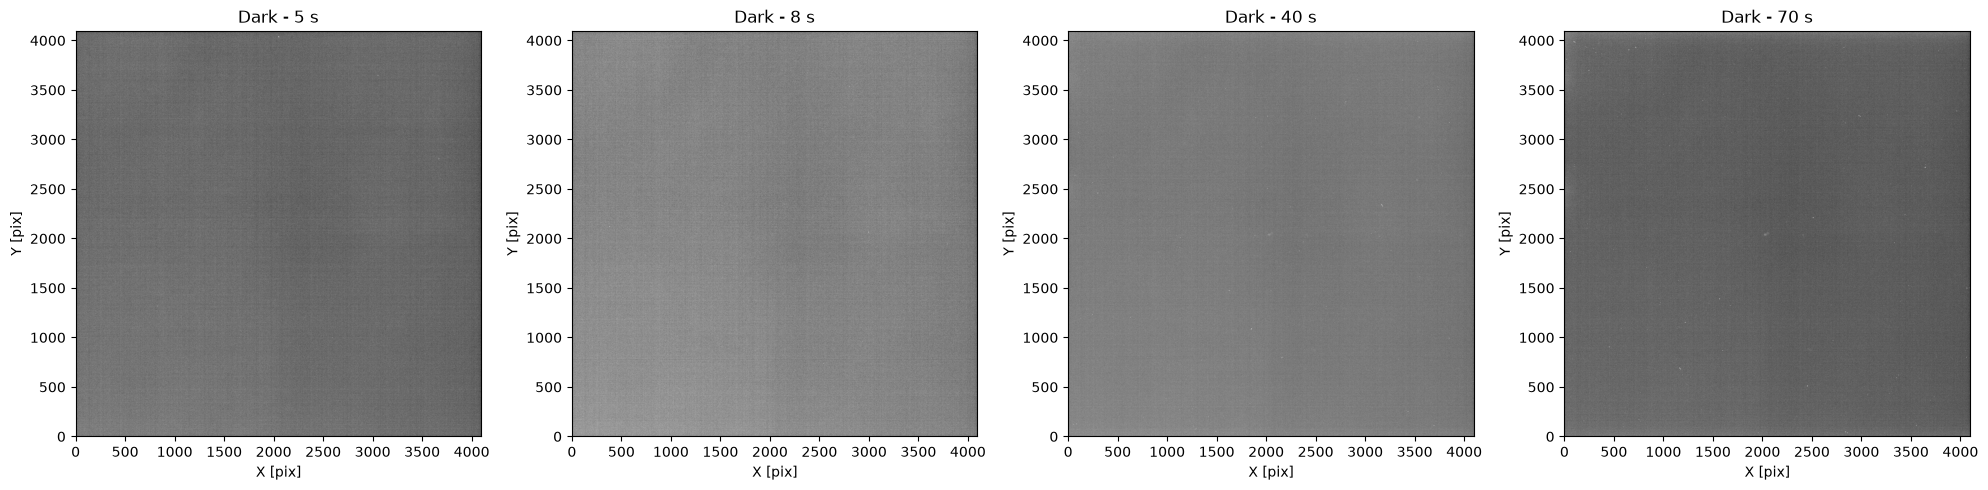

In [32]:
darks_estrellas = [
    dark1e,   # 5 segundos
    dark6e,   # 8 segundos
    dark11e,  # 40 segundos
    dark16e   # 70 segundos
]

titulos_darks = [
    'Dark - 5 s',
    'Dark - 8 s',
    'Dark - 40 s',
    'Dark - 70 s'
]

fig, axes = plt.subplots(1, 4, figsize=(20, 6))

zscale = ZScaleInterval()

for ax, dark, titulo in zip(axes, darks_estrellas, titulos_darks):

    vmin, vmax = zscale.get_limits(dark)

    ax.imshow(
        dark,
        cmap='gray',
        origin='lower',
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(titulo)
    ax.set_xlabel('X [pix]')
    ax.set_ylabel('Y [pix]')

plt.tight_layout()
plt.show()

In [33]:
# Master Dark de cada tiempo de exposición
master_dark5s_e = np.median(
    np.array([dark1e, dark2e, dark3e, dark4e, dark5e]), axis=0
)

master_dark8s_e = np.median(
    np.array([dark6e, dark7e, dark8e, dark9e, dark10e]), axis=0
)

master_dark40s_e = np.median(
    np.array([dark11e, dark12e, dark13e, dark14e, dark15e]), axis=0
)

master_dark70s_e = np.median(
    np.array([dark16e, dark17e, dark18e, dark19e, dark20e]), axis=0
)


# Tiempos de exposición
t1, t2, t3, t4 = 5, 8, 40, 70

# Promedio de los tiempos
t_prom = np.mean([t1, t2, t3, t4])


# Promedio de los Master Dark
dark_prom = (
    master_dark5s_e + master_dark8s_e +
    master_dark40s_e + master_dark70s_e
) / 4


# Corriente oscura (pendiente de la recta)
dark_current = (
    (t1 - t_prom) * master_dark5s_e +
    (t2 - t_prom) * master_dark8s_e +
    (t3 - t_prom) * master_dark40s_e +
    (t4 - t_prom) * master_dark70s_e
) / (
    (t1 - t_prom)**2 +
    (t2 - t_prom)**2 +
    (t3 - t_prom)**2 +
    (t4 - t_prom)**2
)

In [34]:
# HIP 6257
# Filtro B (70 segundos)

red_star_1B_1 = (star_1B_1 - master_dark70s_e) / master_flatb_norm
red_star_1B_2 = (star_1B_2 - master_dark70s_e) / master_flatb_norm
red_star_1B_3 = (star_1B_3 - master_dark70s_e) / master_flatb_norm
red_star_1B_4 = (star_1B_4 - master_dark70s_e) / master_flatb_norm
red_star_1B_5 = (star_1B_5 - master_dark70s_e) / master_flatb_norm

# Filtro V (5 segundos)

red_star_1V_1 = (star_1V_1 - master_dark5s_e) / master_flatv_norm
red_star_1V_2 = (star_1V_2 - master_dark5s_e) / master_flatv_norm
red_star_1V_3 = (star_1V_3 - master_dark5s_e) / master_flatv_norm
red_star_1V_4 = (star_1V_4 - master_dark5s_e) / master_flatv_norm
red_star_1V_5 = (star_1V_5 - master_dark5s_e) / master_flatv_norm
red_star_1V_6 = (star_1V_6 - master_dark5s_e) / master_flatv_norm
red_star_1V_7 = (star_1V_7 - master_dark5s_e) / master_flatv_norm

# HIP 115796
# Filtro B (40 segundos)

red_star_2B_1 = (star_2B_1 - master_dark40s_e) / master_flatb_norm
red_star_2B_2 = (star_2B_2 - master_dark40s_e) / master_flatb_norm
red_star_2B_3 = (star_2B_3 - master_dark40s_e) / master_flatb_norm
red_star_2B_4 = (star_2B_4 - master_dark40s_e) / master_flatb_norm
red_star_2B_5 = (star_2B_5 - master_dark40s_e) / master_flatb_norm

# Filtro V (8 segundos)

red_star_2V_1 = (star_2V_1 - master_dark8s_e) / master_flatv_norm
red_star_2V_2 = (star_2V_2 - master_dark8s_e) / master_flatv_norm
red_star_2V_3 = (star_2V_3 - master_dark8s_e) / master_flatv_norm
red_star_2V_4 = (star_2V_4 - master_dark8s_e) / master_flatv_norm
red_star_2V_5 = (star_2V_5 - master_dark8s_e) / master_flatv_norm

C:\Users\Valem\AppData\Local\Temp\ipykernel_20692\139836346.py:4: RuntimeWarning: invalid value encountered in divide
  red_star_1B_1 = (star_1B_1 - master_dark70s_e) / master_flatb_norm
C:\Users\Valem\AppData\Local\Temp\ipykernel_20692\139836346.py:5: RuntimeWarning: invalid value encountered in divide
  red_star_1B_2 = (star_1B_2 - master_dark70s_e) / master_flatb_norm
C:\Users\Valem\AppData\Local\Temp\ipykernel_20692\139836346.py:6: RuntimeWarning: invalid value encountered in divide
  red_star_1B_3 = (star_1B_3 - master_dark70s_e) / master_flatb_norm
C:\Users\Valem\AppData\Local\Temp\ipykernel_20692\139836346.py:7: RuntimeWarning: invalid value encountered in divide
  red_star_1B_4 = (star_1B_4 - master_dark70s_e) / master_flatb_norm
C:\Users\Valem\AppData\Local\Temp\ipykernel_20692\139836346.py:8: RuntimeWarning: invalid value encountered in divide
  red_star_1B_5 = (star_1B_5 - master_dark70s_e) / master_flatb_norm
C:\Users\Valem\AppData\Local\Temp\ipykernel_20692\139836346.py:12

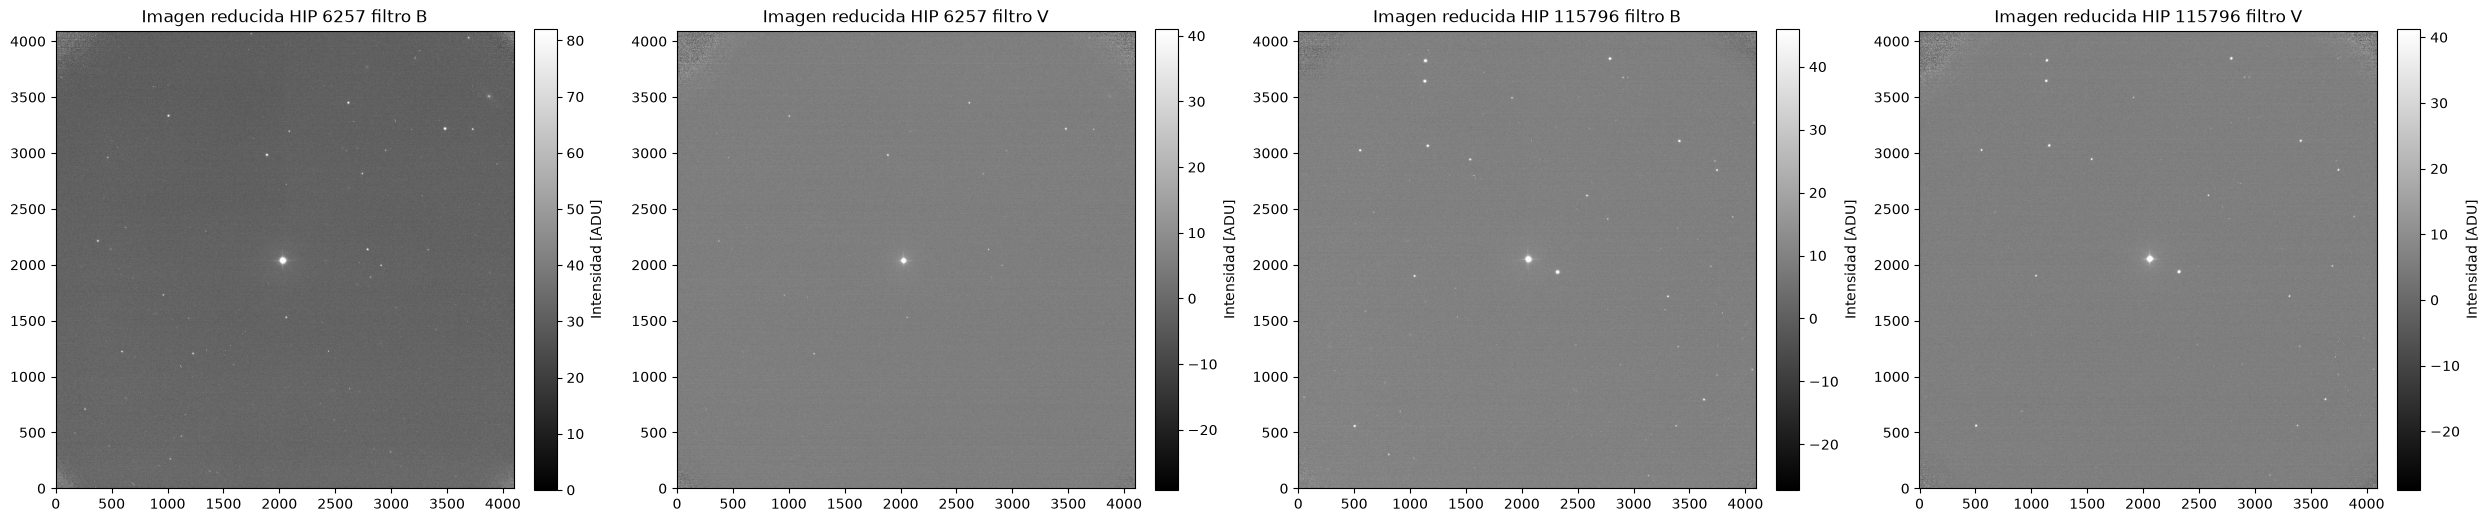

In [35]:
# Graficamos las primeras imagenes cientificas reducidas

zscale = ZScaleInterval(contrast=0.25)

min_b1, max_b1 = zscale.get_limits(red_star_1B_1)
min_v1, max_v1 = zscale.get_limits(red_star_1V_1)

min_b2, max_b2 = zscale.get_limits(red_star_2B_1)
min_v2, max_v2 = zscale.get_limits(red_star_2V_1)


fig, ax = plt.subplots(1, 4, figsize=(25, 10))

HIP6257B = ax[0].imshow(red_star_1B_1, vmin=min_b1, vmax=max_b1,
                        cmap='gray', origin='lower')
ax[0].set_title('Imagen reducida HIP 6257 filtro B')
fig.colorbar(HIP6257B, ax=ax[0], label='Intensidad [ADU]',
             fraction=0.046, pad=0.04)

HIP6257V = ax[1].imshow(red_star_1V_1, vmin=min_v1, vmax=max_v1,
                        cmap='gray', origin='lower')
ax[1].set_title('Imagen reducida HIP 6257 filtro V')
fig.colorbar(HIP6257V, ax=ax[1], label='Intensidad [ADU]',
             fraction=0.046, pad=0.04)

HIP115796B = ax[2].imshow(red_star_2B_1, vmin=min_b2, vmax=max_b2,
                          cmap='gray', origin='lower')
ax[2].set_title('Imagen reducida HIP 115796 filtro B')
fig.colorbar(HIP115796B, ax=ax[2], label='Intensidad [ADU]',
             fraction=0.046, pad=0.04)

HIP115796V = ax[3].imshow(red_star_2V_1, vmin=min_v2, vmax=max_v2,
                          cmap='gray', origin='lower')
ax[3].set_title('Imagen reducida HIP 115796 filtro V')
fig.colorbar(HIP115796V, ax=ax[3], label='Intensidad [ADU]',
             fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

In [36]:
# Imágenes finales combinadas
final_star1B = np.mean([red_star_1B_1, red_star_1B_2, red_star_1B_3, red_star_1B_4, red_star_1B_5], axis=0) * bpm
final_star1V = np.mean([red_star_1V_1, red_star_1V_2, red_star_1V_3, red_star_1V_4, red_star_1V_5, red_star_1V_6, red_star_1V_7], axis=0) * bpm
final_star2B = np.mean([red_star_2B_1, red_star_2B_2, red_star_2B_3, red_star_2B_4, red_star_2B_5], axis=0) * bpm
final_star2V = np.mean([red_star_2V_1, red_star_2V_2, red_star_2V_3, red_star_2V_4, red_star_2V_5], axis=0) * bpm

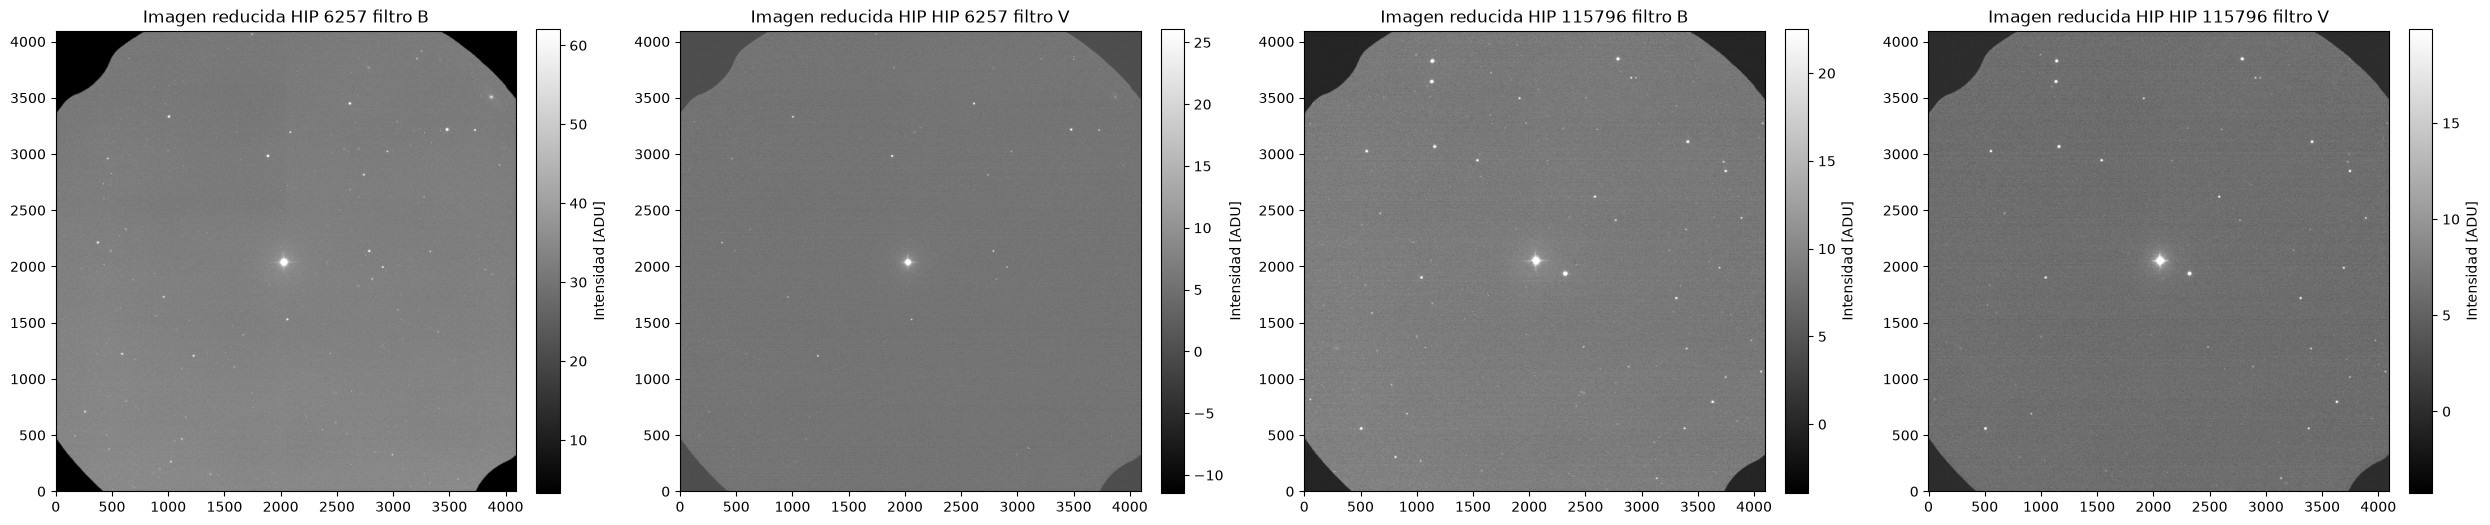

In [37]:
# Graficamos
zscale = ZScaleInterval(contrast=0.25)
min1B, max1B = zscale.get_limits(final_star1B)
min1V, max1V = zscale.get_limits(final_star1V)
min2B, max2B = zscale.get_limits(final_star2B)
min2V, max2V = zscale.get_limits(final_star2V)

# Figura con las 4 imágenes finales
fig, ax = plt.subplots(1, 4, figsize=(25, 10))

# HIP 116375
img1B = ax[0].imshow(final_star1B, vmin=min1B, vmax=max1B, cmap='gray', origin='lower')
ax[0].set_title('Imagen reducida HIP 6257 filtro B')
fig.colorbar(img1B, ax=ax[0], label='Intensidad [ADU]', fraction=0.046, pad=0.04)

img1V = ax[1].imshow(final_star1V, vmin=min1V, vmax=max1V, cmap='gray', origin='lower')
ax[1].set_title('Imagen reducida HIP HIP 6257 filtro V')
fig.colorbar(img1V, ax=ax[1], label='Intensidad [ADU]', fraction=0.046, pad=0.04)

# HIP 117678
img2B = ax[2].imshow(final_star2B, vmin=min2B, vmax=max2B, cmap='gray', origin='lower')
ax[2].set_title('Imagen reducida HIP 115796 filtro B')
fig.colorbar(img2B, ax=ax[2], label='Intensidad [ADU]', fraction=0.046, pad=0.04)

img2V = ax[3].imshow(final_star2V, vmin=min2V, vmax=max2V, cmap='gray', origin='lower')
ax[3].set_title('Imagen reducida HIP HIP 115796 filtro V')
fig.colorbar(img2V, ax=ax[3], label='Intensidad [ADU]', fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

In [38]:
# HIP 6257
# Filtro B

header_B = fits.getheader(ruta_estrellas + r'\HIP_6257_B_70.000secs_00000803.fit')

phdu = fits.PrimaryHDU(header=header_B, data=final_star1B)
phdu.data = np.float32(phdu.data)

phdu.header['PIXSCALE'] = 0.36
phdu.header['CTYPE1'] = 'RA---TAN'
phdu.header['CTYPE2'] = 'DEC--TAN'
phdu.header['CRPIX1'] = int(phdu.header['NAXIS1']/2)
phdu.header['CRPIX2'] = int(phdu.header['NAXIS2']/2)

coord = SkyCoord(f"{phdu.header['OBJCTRA']} {phdu.header['OBJCTDEC']}",
                 unit=(u.hourangle, u.deg))

phdu.header['CRVAL1'] = coord.ra.value
phdu.header['CRVAL2'] = coord.dec.value

phdu.header['CD1_1'] = -0.0001
phdu.header['CD1_2'] = 0
phdu.header['CD2_1'] = 0
phdu.header['CD2_2'] = 0.0001

phdu.header['OBSERVER'] = 'Cortes, Martinez, Soto'

phdu.writeto('Star1_B.fits', overwrite=True)

# HIP 6257
# Filtro V

header_V = fits.getheader(ruta_estrellas + r'\HIP_6257_V_5.000secs_00000808.fit')

phdu = fits.PrimaryHDU(header=header_V, data=final_star1V)
phdu.data = np.float32(phdu.data)

phdu.header['PIXSCALE'] = 0.36
phdu.header['CTYPE1'] = 'RA---TAN'
phdu.header['CTYPE2'] = 'DEC--TAN'
phdu.header['CRPIX1'] = int(phdu.header['NAXIS1']/2)
phdu.header['CRPIX2'] = int(phdu.header['NAXIS2']/2)

coord = SkyCoord(f"{phdu.header['OBJCTRA']} {phdu.header['OBJCTDEC']}",
                 unit=(u.hourangle, u.deg))

phdu.header['CRVAL1'] = coord.ra.value
phdu.header['CRVAL2'] = coord.dec.value

phdu.header['CD1_1'] = -0.0001
phdu.header['CD1_2'] = 0
phdu.header['CD2_1'] = 0
phdu.header['CD2_2'] = 0.0001

phdu.header['OBSERVER'] = 'Cortes, Martinez, Soto'

phdu.writeto('Star1_V.fits', overwrite=True)

In [39]:
# HIP 115796
# Filtro B

header_B = fits.getheader(ruta_estrellas + r'\HIP_115796_B_40.000secs_00000791.fit')

phdu = fits.PrimaryHDU(header=header_B, data=final_star2B)
phdu.data = np.float32(phdu.data)

phdu.header['PIXSCALE'] = 0.36
phdu.header['CTYPE1'] = 'RA---TAN'
phdu.header['CTYPE2'] = 'DEC--TAN'
phdu.header['CRPIX1'] = int(phdu.header['NAXIS1']/2)
phdu.header['CRPIX2'] = int(phdu.header['NAXIS2']/2)

coord = SkyCoord(f"{phdu.header['OBJCTRA']} {phdu.header['OBJCTDEC']}", unit=(u.hourangle, u.deg))

phdu.header['CRVAL1'] = coord.ra.value
phdu.header['CRVAL2'] = coord.dec.value

phdu.header['CD1_1'] = -0.0001
phdu.header['CD1_2'] = 0
phdu.header['CD2_1'] = 0
phdu.header['CD2_2'] = 0.0001

phdu.header['OBSERVER'] = 'Cortes, Martinez, Soto'

phdu.writeto('Star2_B.fits', overwrite=True)

# Filtro V

header_V = fits.getheader(ruta_estrellas + r'\HIP_115796_V_8.000secs_00000796.fit')

phdu = fits.PrimaryHDU(header=header_V, data=final_star2V)
phdu.data = np.float32(phdu.data)

phdu.header['PIXSCALE'] = 0.36
phdu.header['CTYPE1'] = 'RA---TAN'
phdu.header['CTYPE2'] = 'DEC--TAN'
phdu.header['CRPIX1'] = int(phdu.header['NAXIS1']/2)
phdu.header['CRPIX2'] = int(phdu.header['NAXIS2']/2)

coord = SkyCoord(f"{phdu.header['OBJCTRA']} {phdu.header['OBJCTDEC']}", unit=(u.hourangle, u.deg))

phdu.header['CRVAL1'] = coord.ra.value
phdu.header['CRVAL2'] = coord.dec.value

phdu.header['CD1_1'] = -0.0001
phdu.header['CD1_2'] = 0
phdu.header['CD2_1'] = 0
phdu.header['CD2_2'] = 0.0001

phdu.header['OBSERVER'] = 'Cortes, Martinez, Soto'

phdu.writeto('Star2_V.fits', overwrite=True)